# Frequency analysis - Array Vertical
1/3 octave bands
A check at each octave band of the direction of arrival accuracy of each method

All comparisons at H2, the cleanest case

How does accuracy vary with frequency

Using butterworth filters to separate recorded signals into 1/3 octave bands

Accuracy to be checked at each angle, and each band here, but only at H2

This config doesnt seem to be affected by frequency as much, however the spatial accuracy is coarser than the horizontal config

Should be noted that this config is more accurate at lower frequencies compared to the horizontal config. Why? For the 67.5 DOA in particular, that uncertainty seen in the horizontal config can also be seen in the higher frequencies. Why?

In [5]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
from scipy.signal import butter, lfilter, freqz, sosfreqz, sosfiltfilt
import matplotlib.cm as cm

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code") 

from HATS_functions import gcc_phat, corr_to_itd, xcorr_itd_plain

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
PathToFiles = "../Audio_Files/Mic_Array/Vertical/H2"

num_mics = 7
fs = 48000

recordings = {}

for angle in angles:
    folder = Path(PathToFiles) / str(angle)
    if folder.is_dir():
        recordings[angle] = {
                '0': folder / "Untitled 1-Audio.wav",
                '1': folder / "Untitled 2-Audio.wav",
                '2': folder / "Untitled 3-Audio.wav",
                '3': folder / "Untitled 4-Audio.wav",
                '4': folder / "Untitled 5-Audio.wav",
                '5': folder / "Untitled 6-Audio.wav",
                '6': folder / "Untitled 7-Audio.wav",
                '7': folder / "Untitled 8-Audio.wav"
            }
    else:
        print(f"Missing folder: {folder}")

In [6]:
third_octave_centres = [
    125, 160,
    200, 250, 315,
    400, 500, 630,
    800, 1000, 1250,
    1600, 2000, 2500,
    3150, 4000, 5000,
    6300, 8000, 10000,
    12500, 16000
]

def butter_bandpass_sos(lowcut, highcut, fs, order=4):
    sos = butter(order, [lowcut, highcut], btype='band', fs=fs, output='sos')
    return sos

def bandpass_third_octave(signal, fc, fs, order=2):
    low = fc / (2**(1/6))
    high = fc * (2**(1/6))
    high = min(high, fs/2 - 1)
    sos = butter(order, [low, high], btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, signal, axis=0)


In [7]:
r = 0.045
x = 2 * r * np.sin(np.radians(30))
y = 2 * r * np.sin(np.radians(60))
z = 2 * r * np.sin(np.radians(90))

dists = [[0, r, r, r, r, r, r],
         [r, 0, x, y, z, y, x],
         [r, x, 0, x, y, z, y],
         [r, y, x, 0, x, y, z],
         [r, z, y, x, 0, x, y],
         [r, y, z, y, x, 0, x],
         [r, x, y, z, y, x, 0],]

scores = {'0': 0,
          '1': 0,
          '2': 0,
          '3': 0,
          '4': 0,
          '5': 0,
          '6': 0,}

magnitude = {'0': 0,
          '1': 0,
          '2': 0,
          '3': 0,
          '4': 0,
          '5': 0,
          '6': 0,}


results = []

for band in third_octave_centres:
    fcentre = band
    lowcut = fcentre / 2**(1/6)
    highcut = fcentre * 2**(1/6)
    
    scores = {str(i): 0 for i in range(7)}
    
    for i in range(7):
        datax, fs = sf.read(recordings['90'][str(i)])
        if datax.ndim > 1:
            datax = datax.mean(axis=1)
        datax_filt = bandpass_third_octave(datax, fcentre, fs)
        
        for j in range(i + 1, 7):
            datay, _ = sf.read(recordings['90'][str(j)])
            if datay.ndim > 1:
                datay = datay.mean(axis=1)
            datay_filt = bandpass_third_octave(datay, fcentre, fs)
            
            
            itd_filt = xcorr_itd_plain(datax_filt, datay_filt, dists[i][j], fs)
            
            if itd_filt < 0:
                scores[str(i)] += 1
                winner = i
            else:
                scores[str(j)] += 1
                winner = j
            
            results.append({
                'band_hz': band,
                'mic_i': i,
                'mic_j': j,
                'itd_us': itd_filt * 1e6,
                'winner': winner,
            })
    
    results.append({
        'band_hz': band,
        'summary': 'scores',
        **{f'mic_{k}_votes': v for k, v in scores.items()}
    })

df = pd.DataFrame(results)
df.to_csv('freq_analysis_VERTICAL_90deg.csv', index=False)

scores_only = df[df['summary'] == 'scores'].drop(columns=['mic_i', 'mic_j', 'itd_us', 'winner', 'summary'])
print(scores_only.to_string(index=False)) 

 band_hz  mic_0_votes  mic_1_votes  mic_2_votes  mic_3_votes  mic_4_votes  mic_5_votes  mic_6_votes
     125          3.0          4.0          0.0          1.0          2.0          5.0          6.0
     160          3.0          2.0          0.0          1.0          4.0          6.0          5.0
     200          3.0          1.0          0.0          2.0          4.0          6.0          5.0
     250          3.0          1.0          0.0          2.0          4.0          6.0          5.0
     315          3.0          2.0          0.0          1.0          4.0          6.0          5.0
     400          3.0          2.0          0.0          1.0          4.0          6.0          5.0
     500          3.0          1.0          0.0          2.0          4.0          6.0          5.0
     630          3.0          2.0          0.0          1.0          4.0          5.0          6.0
     800          2.0          3.0          0.0          1.0          4.0          5.0          6.0


/var/folders/wl/6gyc0yz53snb8mbsbvf6rnh80000gn/T/ipykernel_85598/1895544831.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper left', bbox_to_anchor=(1.15, 1.0))


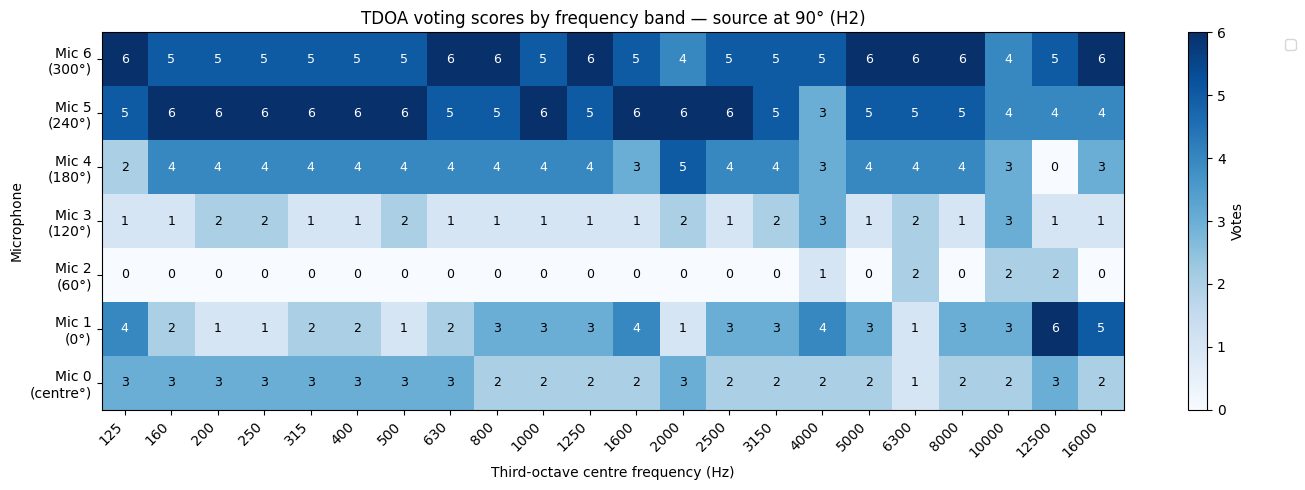

/var/folders/wl/6gyc0yz53snb8mbsbvf6rnh80000gn/T/ipykernel_85598/1895544831.py:70: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')


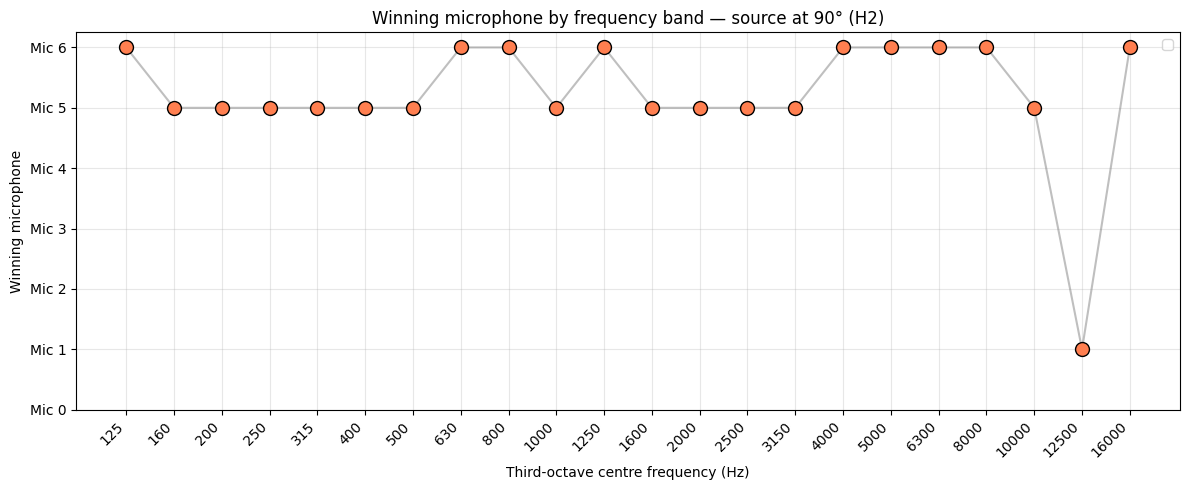

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

df = pd.read_csv('freq_analysis_VERTICAL_90deg.csv')
scores_df = df[df['summary'] == 'scores'].copy()

bands = scores_df['band_hz'].values
mic_labels = [f'Mic {k}\n({[0, 60, 120, 180, 240, 300][k-1] if k > 0 else "centre"}°)' 
              for k in range(7)]
vote_matrix = scores_df[[f'mic_{k}_votes' for k in range(7)]].values.T 

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


# Heatmap

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(vote_matrix, cmap='Blues', aspect='auto', origin='lower', vmin=0, vmax=6)

ax.set_xticks(range(len(bands)))
ax.set_xticklabels([f'{int(b)}' for b in bands], rotation=45, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels(mic_labels)
ax.set_xlabel('Third-octave centre frequency (Hz)')
ax.set_ylabel('Microphone')
ax.set_title('TDOA voting scores by frequency band — source at 90° (H2)')


for i in range(7):
    for j in range(len(bands)):
        val = int(vote_matrix[i, j])
        ax.text(j, i, str(val), ha='center', va='center', fontsize=9,
                color='white' if val >= 4 else 'black')



cbar = fig.colorbar(im, ax=ax, ticks=range(7))
cbar.set_label('Votes')

ax.legend(loc='upper left', bbox_to_anchor=(1.15, 1.0))
plt.tight_layout()
#fig.savefig(figures_dir / 'freq_band_voting_heatmap_90deg.png', dpi=200, bbox_inches='tight')
#fig.savefig(figures_dir / 'freq_band_voting_heatmap_90deg.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)


# Line Plot

winners = np.argmax(vote_matrix, axis=0)
correct = (winners == 2) | (winners == 1)  

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['coral']
ax.scatter(range(len(bands)), winners, c=colors, s=100, edgecolors='black', zorder=3)
ax.plot(range(len(bands)), winners, color='gray', alpha=0.5, zorder=2)


ax.set_xticks(range(len(bands)))
ax.set_xticklabels([f'{int(b)}' for b in bands], rotation=45, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels([f'Mic {k}' for k in range(7)])
ax.set_xlabel('Third-octave centre frequency (Hz)')
ax.set_ylabel('Winning microphone')
ax.set_title('Winning microphone by frequency band — source at 90° (H2)')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
#fig.savefig(figures_dir / 'freq_band_winner_90deg.png', dpi=200, bbox_inches='tight')
#fig.savefig(figures_dir / 'freq_band_winner_90deg.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)

/var/folders/wl/6gyc0yz53snb8mbsbvf6rnh80000gn/T/ipykernel_85598/416947394.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper left', bbox_to_anchor=(1.15, 1.0))


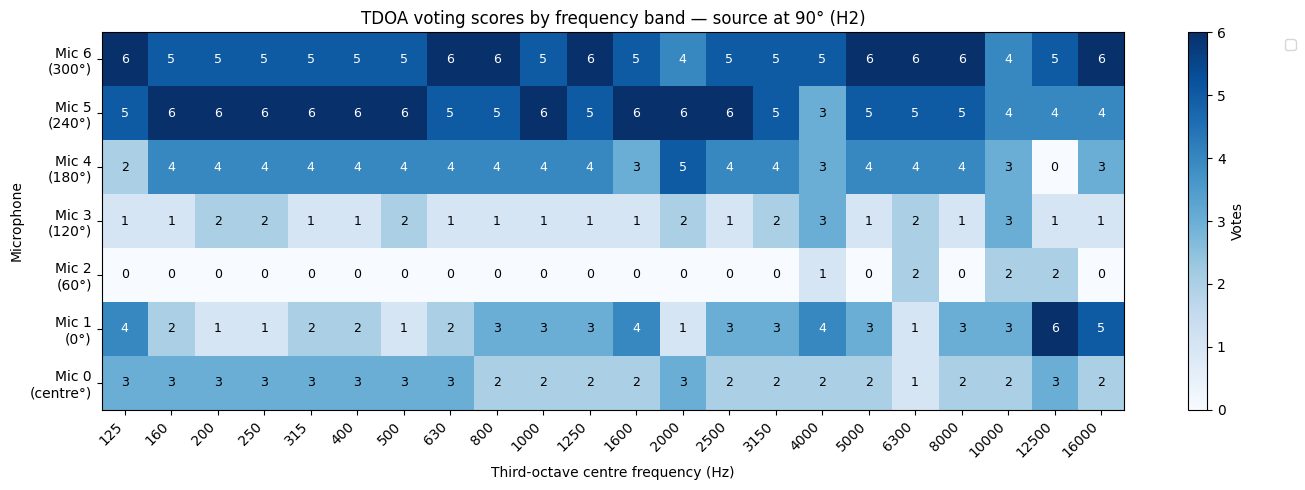

/var/folders/wl/6gyc0yz53snb8mbsbvf6rnh80000gn/T/ipykernel_85598/416947394.py:68: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')


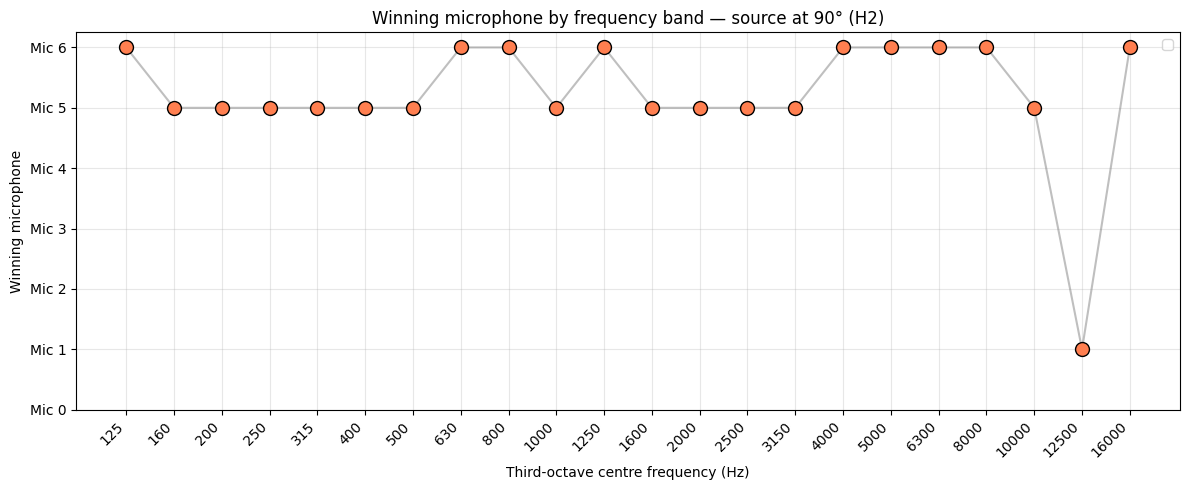

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

df = pd.read_csv('freq_analysis_VERTICAL_90deg.csv')
scores_df = df[df['summary'] == 'scores'].copy()

bands = scores_df['band_hz'].values
mic_labels = [f'Mic {k}\n({[0, 60, 120, 180, 240, 300][k-1] if k > 0 else "centre"}°)' 
              for k in range(7)]
vote_matrix = scores_df[[f'mic_{k}_votes' for k in range(7)]].values.T  # (7, n_bands)

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

# Heatmap

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(vote_matrix, cmap='Blues', aspect='auto', origin='lower', vmin=0, vmax=6)

ax.set_xticks(range(len(bands)))
ax.set_xticklabels([f'{int(b)}' for b in bands], rotation=45, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels(mic_labels)
ax.set_xlabel('Third-octave centre frequency (Hz)')
ax.set_ylabel('Microphone')
ax.set_title('TDOA voting scores by frequency band — source at 90° (H2)')


for i in range(7):
    for j in range(len(bands)):
        val = int(vote_matrix[i, j])
        ax.text(j, i, str(val), ha='center', va='center', fontsize=9,
                color='white' if val >= 4 else 'black')


cbar = fig.colorbar(im, ax=ax, ticks=range(7))
cbar.set_label('Votes')

ax.legend(loc='upper left', bbox_to_anchor=(1.15, 1.0))
plt.tight_layout()
#fig.savefig(figures_dir / 'freq_band_voting_heatmap_45deg.png', dpi=200, bbox_inches='tight')
#fig.savefig(figures_dir / 'freq_band_voting_heatmap_45deg.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)


# Line Plot

winners = np.argmax(vote_matrix, axis=0)
correct = (winners == 2) | (winners == 1)  # true source is between mics 1 & 2

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['coral']
ax.scatter(range(len(bands)), winners, c=colors, s=100, edgecolors='black', zorder=3)
ax.plot(range(len(bands)), winners, color='gray', alpha=0.5, zorder=2)


ax.set_xticks(range(len(bands)))
ax.set_xticklabels([f'{int(b)}' for b in bands], rotation=45, ha='right')
ax.set_yticks(range(7))
ax.set_yticklabels([f'Mic {k}' for k in range(7)])
ax.set_xlabel('Third-octave centre frequency (Hz)')
ax.set_ylabel('Winning microphone')
ax.set_title('Winning microphone by frequency band — source at 90° (H2)')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
#fig.savefig(figures_dir / 'freq_band_winner_45deg.png', dpi=200, bbox_inches='tight')
#fig.savefig(figures_dir / 'freq_band_winner_45deg.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)